# **Redes Neuronales 2**
## Práctica 2: Diferenciación Automática

**Temas:**
- Diferenciación automática (modos directo y reverso).
- Conceptos de PyTorch: autograd, módulos, funciones de activación y de pérdida, optimizadores, datasets/dataloaders.
- Bucle de entrenamiento de un perceptrón multicapa (MLP) sobre datos reales.

In [1]:
# Imports y configuración básica
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)

Usando dispositivo: cpu


---
## Ejercicio 1:

Retomemos el **mapa logístico** $\{\ell_n\}$ visto en la teoría, dado por la relación de recurrencia $\ell_n(x)=r\ell_{n-1}(x)\big(1-\ell_{n-1}(x)\big)$, donde el estado inicial es $\ell_1(x)=x$. Pueden fijar $r=4$ y $n=3$ para simplificar.
- a) ¿Cómo sería el grafo computacional de $\ell_n(x)$? Para construir este grafo, primero a partir de las operaciones base de `suma` y `producto` construir la operación $f(x)=rx(1-x)$, luego usar esta función para construir el grafo de $\ell_n$, con $\ell_0(x)=x$ como el nodo raíz.
- b) Escribir una función que implemente $\ell_n$ usando sólo elementos de la biblioteca estándar de Python, y `numpy` si lo desean. Pueden hacerlo de manera iterativa y/o recursiva.
- c) Escribir una función que calcule $\ell'_n(x)=\frac{d\ell_n(x)}{dx}$, de nuevo usando sólo elementos de la biblioteca estándar:
  - i. Usando diferenciación numérica con diferencias finitas. Observar qué pasa si hacemos variar $h$ en un rango amplio de valores. Examinar cómo depende este comportamiento de que se use `float32` o `float64`. Si usan `numpy`, pueden cambiar el tipo de datos con `numpy.float32` ó `numpy.float64`.
  - ii. Usando diferenciación automática. Como vimos en la teoría, esto implica ir llevando $(\ell_i(x), \ell'_i(x))$ para cada $i$ a partir de 1 hasta llegar a $n$ (en el modo directo), o computar los distintos $\ell_i(x)$ y luego calcular las derivadas en el orden inverso. Nuevamente, la implementación puede ser iterativa o recursiva.
- d) Finalmente, realizar diferenciación automática usando PyTorch.

Las distintas formas exactas deben dar el mismo resultado, lo cual pueden usar para corroborar las soluciones.

In [9]:
r = 4
n=3

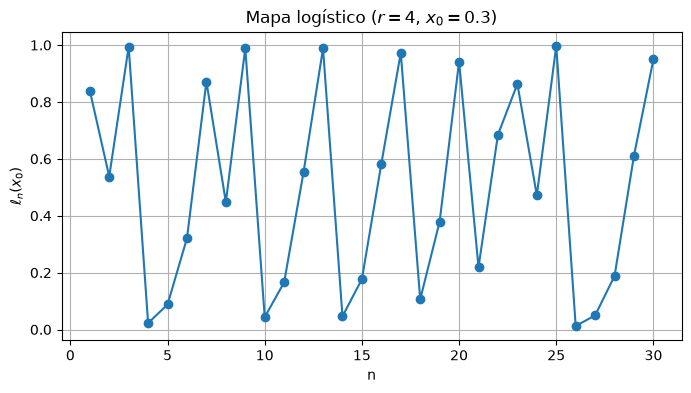

In [10]:
# inciso b: Fucnion recursiva que calcule hasta un n

def logistic_map_iter(x, n, r=4):
    l = x
    for _ in range(n):
        l = r * l * (1 - l)
    return l

import matplotlib.pyplot as plt

x0 = 0.3
n_max = 30
ns = list(range(1, n_max + 1))
valores = [logistic_map_iter(x0, n,r) for n in ns]

plt.figure(figsize=(8, 4))
plt.plot(ns, valores, marker='o')
plt.xlabel('n')
plt.ylabel(r'$\ell_n(x_0)$')
plt.title(fr'Mapa logístico ($r=4$, $x_0={x0}$)')
plt.grid(True)
plt.show()


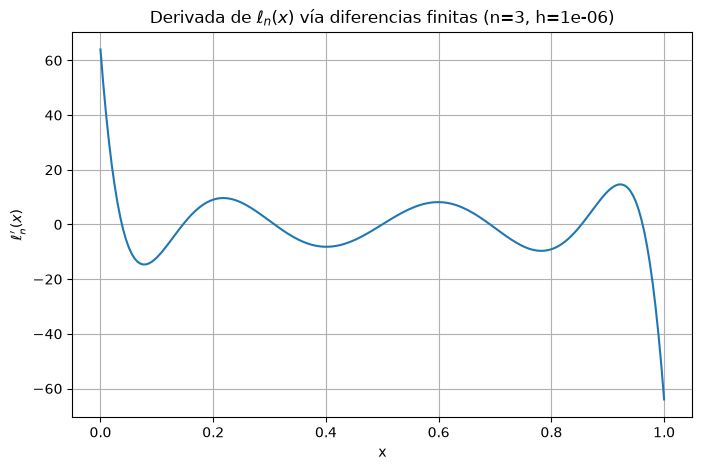

In [11]:
# vamos a resovler esto de diferencias finitas

def derivada_diferencias_finitas(x, n, h, r=4, dtype=np.float64):
    x = dtype(x)
    h = dtype(h)
    l_mas = logistic_map_iter(x + h, n, r) #calcula el punto siguiente
    l_menos = logistic_map_iter(x - h, n, r) #calcula el punto anterior
    return (l_mas - l_menos) / (dtype(2) * h) #hace la diferencia y lo divide por el salto

h_fijo = 1e-6

xs = np.linspace(0, 1, 200)
derivadas = [derivada_diferencias_finitas(x, n, h_fijo, dtype=np.float64) for x in xs]

plt.figure(figsize=(8, 5))
plt.plot(xs, derivadas)
plt.xlabel('x')
plt.ylabel(r"$\ell_n'(x)$")
plt.title(fr"Derivada de $\ell_n(x)$ vía diferencias finitas (n={n}, h={h_fijo})")
plt.grid(True)
plt.show()



In [18]:
# usando derivacion automatica

def f(x,r):
    return r*x*(1-x)

def f_p(x,r):
    return r-2*r*x


def deriv_n_directo(n, x_0,r):
    v=x_0
    dv = 1
    for i in range (n):
        d_ix = f_p(v,r)*dv #calculo la derivada

        #cambio los valores
        v = f(v,r)
        dv = d_ix

    return v,dv

In [19]:
def deriv_n_reverso(n, x_0, r):
    #paso 1: Forward. Necesito todos los valores
    valores = [x_0]
    v = x_0

    for i in range(n):
        v = f(v,r) #calculo las imagenes
        valores.append(v)


    #paso 2 backward(). ACumulo la derivada con la regla de la cadena
    dv = 1
    for i in range(n, 0, -1):
        dv = dv*f_p(valores[i-1], r)

    return valores[-1], dv

In [20]:
x0 = 0.3
n = 3
r = 4

# Modo directo
v_dir, dv_dir = deriv_n_directo(n, x0, r)

# Modo inverso
v_rev, dv_rev = deriv_n_reverso(n, x0, r)

# Diferencias finitas (como referencia, del ítem c-i)
dv_fd = derivada_diferencias_finitas(x0, n, h=1e-6, r=r, dtype=np.float64)

print(f"{'Método':<20}{'l_n(x0)':>15}{'l_n\'(x0)':>18}")
print("-" * 53)
print(f"{'Modo directo':<20}{v_dir:>15.10f}{dv_dir:>18.10f}")
print(f"{'Modo inverso':<20}{v_rev:>15.10f}{dv_rev:>18.10f}")
print(f"{'Dif. finitas':<20}{'—':>15}{dv_fd:>18.10f}")

# Chequeo de consistencia
assert abs(v_dir - v_rev) < 1e-10, "Los valores de l_n no coinciden"
assert abs(dv_dir - dv_rev) < 1e-10, "Las derivadas (directo vs inverso) no coinciden"
assert abs(dv_dir - dv_fd) < 1e-4, "La derivada AD no coincide con diferencias finitas"
print("\n✅ Todo coincide")


Método                      l_n(x0)          l_n'(x0)
-----------------------------------------------------
Modo directo           0.9943449600      1.3090816000
Modo inverso           0.9943449600      1.3090816000
Dif. finitas                      —      1.3090816000

✅ Todo coincide


In [ ]:
def deriv_n_pytorch(n,x_0,r):
    x = torch.tensor(x_0, dtype = torch.float64, requires_grad=True) 
    #requires grad es una propiedad de los tensores. Necesitamos calcular la derivada respecto a x en algun momento

    v=x
    for i in range(n):
        v = r*v*(1-v) #fue cambiando los valores entonces tiene un gradiente

    v.backward() #modo inverso. Recorre el grafo que armaste y calculales la derivada

    return v.item(), x.grad.item()


v_torch, dv_torch = deriv_n_pytorch(n, x0, r)
print(f"{'PyTorch':<20}{v_torch:>15.10f}{dv_torch:>18.10f}")

assert abs(v_torch - v_dir) < 1e-10
assert abs(dv_torch - dv_dir) < 1e-10
print("✅ Coincide con los métodos manuales")

PyTorch                0.9943449600      1.3090816000
✅ Coincide con los métodos manuales


---
## Ejercicio 2:

Retomemos la función de dos variables vista en la clase teórica, $f(x_1,x_2)= \ln(x_1) + x_1 x_2 - \sin(x_2)$.
- a) Construir el grafo computacional, donde las funciones base sean $+$, $-$,$\times$, $\sin$ y $\log$ (es decir, cada nodo debe realizar sólo una de estas operaciones)
- b) Implementar el modo reverso de cómputo de gradientes con Python puro, como fue realizado en la teoría.
- c) Implementar lo mismo pero ir guardando en cada paso tanto el valor del nodo como de las derivadas del mismo respecto a las entradas.
- d) Implementar lo mismo pero en PyTorch.

In [ ]:
#voy a construir el grafo
import numpy as np

nodes = {}

nodes["v-1"]={"value":2, "parents": []}
nodes["v0"]={"value":5.0, "parents":[]}

nodes["v1"]={"value": np.log(nodes["v-1"]["value"]),
             "parents":[("v-1", 1/nodes["v-1"]["value"])]}

nodes["v2"] ={"value": nodes["v-1"]["value"]* nodes["v0"]["value"],
              "parents": [
                  ("v-1", nodes["v0"]["value"]),
                  ("v0", nodes["v-1"]["value"])
              ]}

nodes["v3"] = {"value": np.sin(nodes["v0"]["value"]),
               "parents": [("v0", np.cos(nodes["v0"]["value"]))]} # sin(v0)

nodes["v4"] = {"value": nodes["v1"]["value"]+nodes["v2"]["value"],
               "parents": [("v1", 1.0), ("v2", 1.0)]}               # suma

nodes["v5"] = {"value": nodes["v4"]["value"]-nodes["v3"]["value"],
               "parents": [("v4", 1.0), ("v3", -1.0)]}



x1_bar = 5.5
x2_bar = 1.7163378145367738


In [30]:
grad = {}
for name in nodes:
    grad[name] = 0.0 #inicializo todos los gradientes en cero
    
grad["v5"] = 1.0 #este ultimo en 1

print(grad)
for name in reversed(list(nodes.keys())):
    for (parent, local_deriv) in nodes[name]["parents"]:
        grad[parent] += grad[name] * local_deriv

print("x1_bar =", grad["v-1"])   # debería dar 5.5
print("x2_bar =", grad["v0"])   

print(grad)

{'v-1': 0.0, 'v0': 0.0, 'v1': 0.0, 'v2': 0.0, 'v3': 0.0, 'v4': 0.0, 'v5': 1.0}
x1_bar = 5.5
x2_bar = 1.7163378145367738
{'v-1': 5.5, 'v0': np.float64(1.7163378145367738), 'v1': 1.0, 'v2': 1.0, 'v3': -1.0, 'v4': 1.0, 'v5': 1.0}


In [31]:
# 2b
x1 = torch.tensor(2.0, dtype=torch.float64, requires_grad=True)
x2 = torch.tensor(5.0, dtype=torch.float64, requires_grad=True)

f = torch.log(x1) + x1 * x2 - torch.sin(x2)

f.backward()

print(f"f({x1.item()}, {x2.item()}) = {f.item()}")
print(f"df/dx1 = {x1.grad.item()}")
print(f"df/dx2 = {x2.grad.item()}")



f(2.0, 5.0) = 11.652071455223084
df/dx1 = 5.5
df/dx2 = 1.7163378145367738


---
## Ejercicio 3:

Dadas las siguientes dos funciones:
- 1) $f(x, y, z, w) = -zx^2 + 2wy$ evaluada en el punto $(x,y,z,w)=(2,4,1,3)$,
- 2) $g(x,y,z,w) = -3\big(4xy + \max(w, z)\big)$ evaluada en el punto $(x,y,z,w)=(5,2,4,3)$,

se solicita:

- a) Dibujar el grafo computacional, las funciones base ahora serían $+$, $\times$ y $\max$ (y $(⋅)^2$ si lo desean).
- b) Obtener las derivadas manualmente por el modo reverso.
- c) Implementar el modo reverso con Python estándar (sin PyTorch).
- d) Implementarlo con PyTorch.

In [36]:
x = torch.tensor(2, dtype = torch.float32, requires_grad=True)
y = torch.tensor(4, dtype = torch.float32, requires_grad=True)
z = torch.tensor(1, dtype = torch.float32, requires_grad=True)
w = torch.tensor(3, dtype = torch.float32, requires_grad=True)

f = -z*x**2+2*w*y

f.backward()

print(x.grad)
print(y.grad)
print(z.grad)
print(w.grad)

tensor(-4.)
tensor(6.)
tensor(-4.)
tensor(8.)


In [38]:
x = torch.tensor(5, dtype = torch.float32, requires_grad=True)
y = torch.tensor(2, dtype = torch.float32, requires_grad=True)
z = torch.tensor(3, dtype = torch.float32, requires_grad=True)
w = torch.tensor(4, dtype = torch.float32, requires_grad=True)

f = -3*(4*x*y+torch.max(w,z))

f.backward()

print(x.grad)
print(y.grad)
print(z.grad)
print(w.grad)

tensor(-24.)
tensor(-60.)
tensor(0.)
tensor(-3.)


---
## Ejercicio 4:

Implementar el algoritmo de gradiente descendente, utilizando diferenciación automática, para minimizar la función cuadrática: $f(x) = 2x^2 + x + 4$
- a) Sin usar optimizador.
- b) Usando el SGD de `torch.optim` como optimizador.

El mínimo analítico es $f'(x)=4x+1=0 \Rightarrow x^*=-\tfrac14$, con $f(x^*)=2\cdot\tfrac1{16}-\tfrac14+4=\tfrac{31}{8}=3.875$. Lo usamos para chequear que el descenso converge al lugar correcto.

In [39]:
def f(x):
    return 2 * x**2 + x + 4


# Hiperparámetros
x = torch.tensor(5.0, requires_grad=True)  # punto inicial, arbitrario
lr = 0.1
n_iter = 100

historial_x = [x.item()]
historial_f = [f(x).item()]

for i in range(n_iter):
    y = f(x) #evaluo la funcion
    y.backward()  # calcula df/dx y lo guarda en x.grad

    with torch.no_grad():  # la actualización NO debe ser parte del grafo
        x -= lr * x.grad

    x.grad.zero_()  # muy importante: resetear el gradiente antes de la próxima iteración

    historial_x.append(x.item())
    historial_f.append(f(x).item())

print(f"x final = {x.item():.6f}  (esperado: -0.25)")
print(f"f(x final) = {f(x).item():.6f}  (esperado: 3.875)")


x final = -0.250000  (esperado: -0.25)
f(x final) = 3.875000  (esperado: 3.875)


In [40]:
x = torch.tensor(5.0, requires_grad=True)
lr = 0.1
n_iter = 100

optimizador = torch.optim.SGD([x], lr=lr)

historial_x = [x.item()]
historial_f = [f(x).item()]

for i in range(n_iter):
    optimizador.zero_grad()  # resetea los gradientes (equivalente a x.grad.zero_())

    y = f(x)
    y.backward()             # calcula el gradiente

    optimizador.step()       # hace la actualización x -= lr * x.grad (equivalente al with torch.no_grad())

    historial_x.append(x.item())
    historial_f.append(f(x).item())

print(f"x final = {x.item():.6f}  (esperado: -0.25)")
print(f"f(x final) = {f(x).item():.6f}  (esperado: 3.875)")


x final = -0.250000  (esperado: -0.25)
f(x final) = 3.875000  (esperado: 3.875)


---

## Ejercicio 5:

En este ejercicio recapitulamos el **perceptrón multicapa (MLP)** que implementamos en la **Guía 1** y lo usamos en un bucle de entrenamiento completo sobre el dataset `Iris`, aprovechando ahora todas las prestaciones de PyTorch (`Dataset`, `DataLoader`, optimizadores). La tarea es clasificar la especie de planta en base a distintas dimensiones de la flor.

**El modelo ya está dado** en la celda de abajo: es el mismo `PerceptronMulticapa` de la Guía 1 (una capa oculta con activación ReLU). Tu tarea es armar el resto del flujo de entrenamiento:

- a) Primero que nada, debemos [descargar la base de datos de Iris](https://www.kaggle.com/datasets/uciml/iris) y agregarla a nuestro entorno. Es simplemente un archivo CSV.
- b) Crear una clase que implemente un dataset de PyTorch, heredando de `torch.utils.data.Dataset`. Recordar que esto implica definir los dos métodos especiales `__getitem__` y `__len__`. El constructor debe recibir como argumento la ruta al archivo `Iris.csv` que descargaron antes.
- c) Crear particiones de datos de entrenamiento y testeo, con sus respectivos `Dataset` y `DataLoader`. **Ayuda**: recordar la función `sklearn.model_selection.train_test_split`. También existe `torch.utils.data.random_split` para el mismo fin.
- d) Inicializar el modelo dado, la función de pérdida `torch.nn.CrossEntropyLoss` y un optimizador tipo SGD.
- e) Escribir y ejecutar el bucle de entrenamiento. Debe haber dos bucles, el externo sobre las épocas y el interno sobre los batches (es decir, iterando sobre el `DataLoader`). Entrenar por un número fijo de épocas y, al final, reportar la exactitud (_accuracy_) en entrenamiento y en test.

In [41]:
# El modelo ya está dado: es el mismo Perceptrón Multicapa (MLP) que implementaron en la
# Guía 1. Una capa oculta con activación ReLU; la salida son logits (sin activación final),
# porque nn.CrossEntropyLoss ya aplica la softmax internamente.
class PerceptronMulticapa(nn.Module):
    def __init__(self, n_entradas, n_ocultas, n_salidas, salida_sigmoidea=False):
        super().__init__()
        self.capa_oculta = nn.Linear(n_entradas, n_ocultas)
        self.relu = nn.ReLU()
        self.capa_salida = nn.Linear(n_ocultas, n_salidas)
        self.salida_sigmoidea = salida_sigmoidea

    def forward(self, x):
        h = self.relu(self.capa_oculta(x))
        y = self.capa_salida(h)
        if self.salida_sigmoidea:
            y = torch.sigmoid(y)
        return y

print(PerceptronMulticapa(4, 16, 3))

PerceptronMulticapa(
  (capa_oculta): Linear(in_features=4, out_features=16, bias=True)
  (relu): ReLU()
  (capa_salida): Linear(in_features=16, out_features=3, bias=True)
)


In [42]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

iris = load_iris()

In [48]:
X= iris.data
y =iris.target

X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size = 0.2, stratify= y)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size = 0.2, stratify = y_tmp)

In [49]:
class irisDataset(Dataset):
    def __init__(self, X,y):
        self.X = torch.tensor(X, dtype = torch.float32)
        self.y = torch.tensor(y, dtype = torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

In [50]:
train_df = irisDataset(X_train, y_train)
val_df = irisDataset(X_val, y_val)
test_df = irisDataset(X_test, y_test)

train_loader = DataLoader(train_df, batch_size = 32, shuffle = True) #para que en cada epoca vea batches en distinto orden
val_loader = DataLoader(val_df, batch_size = 32, shuffle = False)
test_loader = DataLoader(test_df, batch_size = 32, shuffle = False)

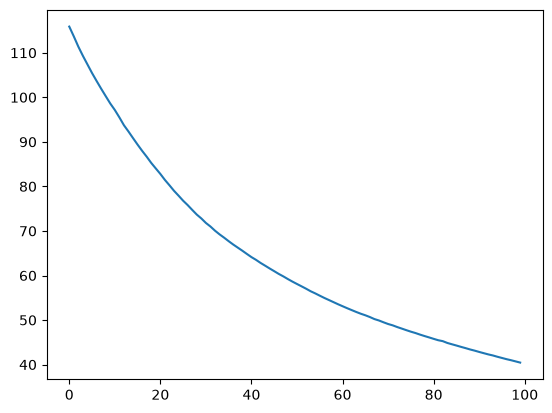

In [56]:
# hacemos un modelo
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

modelo = PerceptronMulticapa(n_entradas = 4, n_ocultas = 16, n_salidas = 3, salida_sigmoidea = False)
loss_func = nn.CrossEntropyLoss() #usa mean
optim = torch.optim.Adam(modelo.parameters(), lr = 1e-3)




modelo.train()

train = []


for i in range(100):
    epoch_loss = 0
    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        optim.zero_grad()
        out = modelo.forward(X)

        loss = loss_func(out, y)
        loss.backward() #acualizamos
        optim.step()

        epoch_loss += loss.item() * len(X)
    train.append(epoch_loss)


plt.plot(train)

